Single Dense Layer Network

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt    

In [4]:
# Data Loading
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size=50
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=2)
testset=torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
testloader=torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=2)
classes=('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

100%|██████████| 170M/170M [1:09:01<00:00, 41.2kB/s] 


In [5]:
# Define Network Parameters
Din=3*32*32 #Input size (Flattened CIFAR-10 image size)
K=10 #Output size (Number of classes in CIFAR-10)
H=100 #middle layer with 100 nodes
std=1e-5

# Initialize weights and biases
#w=torch.randn(Din,K)*std #One layer: directly map input to output
#b=torch.zeros(K)
w1=torch.randn(Din,H)*std
b1=torch.zeros(H)

w2=torch.randn(H,K)*std
b2=torch.zeros(K)

# Hyperparameters
iterations=10
lr=2e-6 #learning rate
lr_decay=0.9 #learning rate decay
reg=0 #regularization
loss_history=[]

In [6]:
# Training Loop
for t in range(iterations):
    running_loss=0.0
    for i,data in enumerate(trainloader,0):
        #Get inputs and labels
        inputs,labels=data
        Ntr=inputs.shape[0] # Batch size
        x_train=inputs.view(Ntr,-1) #Flatten input to (Ntr,Din)
        y_train_onehot=nn.functional.one_hot(labels,K).float() # Convert labels to one hot

        #Forward pass
        #y_pred=x_train.mm(w)+b #output layer activation
        # Hidden Layer
        z1=x_train.mm(w1)+b1
        h=torch.sigmoid(z1)
        # Output layer
        y_pred=h.mm(w2)+b2

        #Loss calculation (mean square error with regularization)
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*torch.sum(w**2))
        #MSE Loss
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*(torch.sum(w1**2)+torch.sum(w2**2)))

        # Cross Entropy Loss
        loss=nn.functional.cross_entropy(y_pred,labels)+reg*(torch.sum(w1**2)+torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss+=loss.item()

        #Backpropagation
        #dy_pred=(2.0/Ntr)*(y_pred-y_train_onehot)
        #Backpropagation - logit
        probs=torch.softmax(y_pred,dim=1)
        dy_pred=(probs-y_train_onehot)/Ntr

        #dw=x_train.t().mm(dy_pred)+reg*w
        #db=dy_pred.sum(dim=0)

        # output layer
        dw2=h.t().mm(dy_pred)+2*reg*w2
        db2=dy_pred.sum(dim=0)
        #Hidden layer
        dh=dy_pred.mm(w2.t())
        dz1=dh*h*(1-h)
        dw1=x_train.t().mm(dz1)+2*reg*w1
        db1=dz1.sum(dim=0)

        #Parameter update
        #w-=lr*dw
        #b-=lr*db
        with torch.no_grad():
            w1-=lr*dw1
            b1-=lr*db1
            w2-=lr*dw2
            b2-=lr*db2

    # Print loss for every epoch
    if t%1==0:
        print(f"Epoch_{t+1}/{iterations},_Loss:_{running_loss/len(trainloader)}")
    #Learning rate decay
    lr*=lr_decay

Epoch_1/10,_Loss:_2.302585562944412
Epoch_2/10,_Loss:_2.3025855095386505
Epoch_3/10,_Loss:_2.302585464715958
Epoch_4/10,_Loss:_2.3025854189395902
Epoch_5/10,_Loss:_2.3025853941440584
Epoch_6/10,_Loss:_2.3025853452682497
Epoch_7/10,_Loss:_2.3025853133201597
Epoch_8/10,_Loss:_2.302585292339325
Epoch_9/10,_Loss:_2.302585295200348
Epoch_10/10,_Loss:_2.3025852608680726


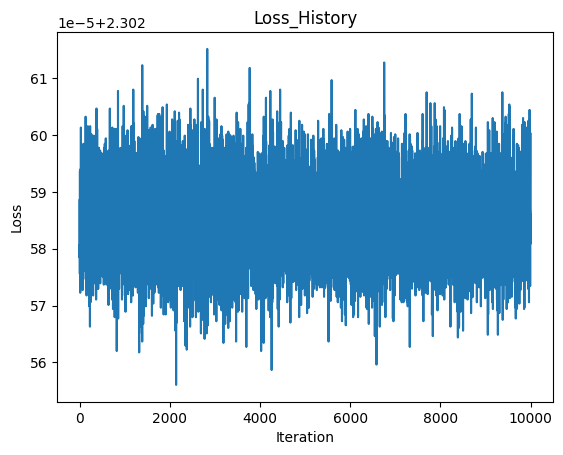

In [7]:
#Plotting Loss history
plt.plot(loss_history)
plt.title("Loss_History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [8]:
# calculate accuracy on Training Set
correct_train=0
total_train=0
with torch.no_grad():
    for data in trainloader:
        inputs,labels=data
        Ntr=inputs.shape[0]
        x_train=inputs.view(Ntr,-1)
        y_train_onehot=nn.functional.one_hot(labels,K).float()

        #Forward pass
        h=torch.sigmoid(x_train.mm(w1)+b1)
        y_train_pred=h.mm(w2)+b2
        predicted_train=torch.argmax(y_train_pred,dim=1)
        total_train+=labels.size(0)
        correct_train+=(predicted_train==labels).sum().item()
        
train_acc=100*correct_train/total_train
print(f"Training_accuracy: {train_acc:.2f}%")

Training_accuracy: 10.00%


In [9]:
# Calculate accuracy on Test Set
correct_test=0
total_test=0
with torch.no_grad():
    for data in testloader:
        inputs,labels=data
        Nte=inputs.shape[0]
        x_test=inputs.view(Nte,-1)
        y_test_onehot=nn.functional.one_hot(labels,K).float()

        # Forward Pass
        h=torch.sigmoid(x_test.mm(w1)+b1)
        y_test_pred=h.mm(w2)+b2
        predicted_test=torch.argmax(y_test_pred,dim=1)
        total_test+=labels.size(0)
        correct_test+=(predicted_test==labels).sum().item()

test_acc=100*correct_test/total_test
print(f"Test_accuracy: {test_acc:.2f}%")

Test_accuracy: 10.00%


A two-layer neural network was implemented by adding a hidden layer containing 100 neurons with sigmoid activation to the original single-layer network. Cross-entropy loss was used for classification, and the gradients were calculated manually using backpropagation. The network was trained on the CIFAR-10 dataset for 10 epochs.

The resulting training accuracy was 10%, and the test accuracy was 10%. These results indicate the model's performance on the training and unseen test datasets. The difference between the two accuracies can provide an indication of how well the network generalizes to unseen images.